In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#### Import Data



In [ ]:
df = pd.read_excel('sheep_results.xlsx', sheet_name='Results')
df = df.drop(columns=['Notes'])

In [3]:
df.head()

,Detector,Tracker,HOTA,DetA,DetRe,DetPr,AssA,AssRe,AssPr,IDF1,Det,GT_Det,ID,GT_ID,|ID-GT_ID|,IDSW
0,YOLOv8n,SORT,47.202,35.853,39.067,76.834,62.145,64.441,88.760,54.213,812,1597,10,10,0,2
1,YOLOv8n,BoTSORT,51.931,38.631,46.169,68.018,69.838,72.718,91.022,55.875,1084,1597,14,10,4,1
2,YOLOv8n,DeepSORT,43.463,35.377,41.364,66.190,53.406,59.031,73.302,52.254,998,1597,12,10,2,12
3,YOLOv8n,ByteTrack,52.259,40.399,44.851,77.350,67.634,70.265,91.268,57.471,926,1597,12,10,2,1
4,YOLOv8l,SORT,55.815,46.375,48.209,87.389,67.177,69.633,90.279,63.358,881,1597,13,10,3,1


### Based on HOTA

In [4]:
df.groupby('Tracker')[['HOTA','IDF1']].agg(['mean','min','max']).sort_values(('HOTA', 'mean'), ascending=False).round(3)

HOTA                    IDF1                
             mean     min     max    mean     min     max
Tracker                                                  
ByteTrack  57.709  51.900  60.834  62.181  54.414  66.022
BoTSORT    54.636  48.840  57.386  57.385  49.393  61.649
SORT       53.754  47.202  57.828  60.905  54.205  65.246
DeepSORT   47.456  39.958  51.731  56.046  43.113  62.982

### Based on Detections (Det)

In [5]:
df.groupby('Tracker')[['DetA','DetRe','DetPr','Det','GT_Det']].agg(['mean']).sort_values(('DetA', 'mean'), ascending=False).round(3)

,DetA,DetRe,DetPr,Det,GT_Det
,mean,mean,mean,mean,mean
Tracker,,,,,
ByteTrack,47.946,50.738,86.629,935.333,1597.0
SORT,44.682,46.935,84.959,880.667,1597.0
DeepSORT,43.842,47.765,77.557,983.444,1597.0
BoTSORT,42.585,51.400,69.407,1184.333,1597.0


### Based on Association(AssA)

In [6]:
df.groupby('Tracker')[['AssA','AssRe','AssPr','|ID-GT_ID|','IDSW']].agg(['mean']).sort_values(('AssA', 'mean'), ascending=False).round(3)

,AssA,AssRe,AssPr,|ID-GT_ID|,IDSW
,mean,mean,mean,mean,mean
Tracker,,,,,
BoTSORT,70.266,73.134,91.985,2.778,2.444
ByteTrack,69.635,72.284,92.364,1.778,2.667
SORT,64.827,67.637,89.359,2.000,2.556
DeepSORT,51.681,57.571,73.553,4.889,15.000


## Detectors (Keeping bytetrack as tracker)

### l versions

In [8]:
df_det = df[df['Tracker']=='ByteTrack']
df_det.head()

,Detector,Tracker,HOTA,DetA,DetRe,DetPr,AssA,AssRe,AssPr,IDF1,Det,GT_Det,ID,GT_ID,|ID-GT_ID|,IDSW
3,YOLOv8n,ByteTrack,52.259,40.399,44.851,77.350,67.634,70.265,91.268,57.471,926,1597,12,10,2,1
7,YOLOv8l,ByteTrack,59.328,49.312,51.847,88.179,71.427,73.807,93.312,64.432,939,1597,12,10,2,3
11,YOLOv8x,ByteTrack,60.452,49.824,52.737,87.548,73.436,76.039,93.637,64.244,962,1597,12,10,2,2
15,YOLOv10n,ByteTrack,53.021,41.488,46.004,78.075,67.822,69.936,91.974,58.629,941,1597,13,10,3,3
19,YOLOv10l,ByteTrack,60.308,51.689,54.602,88.349,70.454,73.194,92.816,66.022,987,1597,12,10,2,2


In [9]:
cols = ["Detector", "HOTA", "DetA", "DetRe", "DetPr", "AssA", "IDF1", "IDSW"]

In [10]:
df_det[df_det["Detector"].str.endswith("n")][cols].sort_values("HOTA", ascending=False).round(2)

,Detector,HOTA,DetA,DetRe,DetPr,AssA,IDF1,IDSW
15,YOLOv10n,53.02,41.49,46.00,78.08,67.82,58.63,3
3,YOLOv8n,52.26,40.40,44.85,77.35,67.63,57.47,1
27,YOLO11n,51.90,45.23,47.66,86.10,59.78,54.41,4


In [11]:
df_det[df_det["Detector"].str.endswith("l")][cols].sort_values("HOTA", ascending=False).round(2)

,Detector,HOTA,DetA,DetRe,DetPr,AssA,IDF1,IDSW
31,YOLO11l,60.83,51.20,52.99,91.49,72.34,64.95,2
19,YOLOv10l,60.31,51.69,54.60,88.35,70.45,66.02,2
7,YOLOv8l,59.33,49.31,51.85,88.18,71.43,64.43,3


In [12]:
df_det[df_det["Detector"].str.endswith("x")][cols].sort_values("HOTA", ascending=False).round(2)

,Detector,HOTA,DetA,DetRe,DetPr,AssA,IDF1,IDSW
35,YOLO11x,60.70,51.73,53.75,90.54,71.30,64.99,5
23,YOLOv10x,60.58,50.65,52.21,92.02,72.52,64.48,2
11,YOLOv8x,60.45,49.82,52.74,87.55,73.44,64.24,2


**Model size matters**: n is about 9 HOTA points below l and x.


Version doesn't matter much: at the same size, v8, v10 and v11 land within 0.25 HOTA.

In [13]:
df_det[df_det["Detector"].str.startswith('YOLO11')][cols].sort_values("HOTA", ascending=False).round(2)


,Detector,HOTA,DetA,DetRe,DetPr,AssA,IDF1,IDSW
31,YOLO11l,60.83,51.20,52.99,91.49,72.34,64.95,2
35,YOLO11x,60.70,51.73,53.75,90.54,71.30,64.99,5
27,YOLO11n,51.90,45.23,47.66,86.10,59.78,54.41,4


### Size vs version (HOTA)

In [ ]:
(
    df_det.assign(
        version=df_det["Detector"].str.extract(r"(?i)(yolo(?:v)?\d+)", expand=False),
        size=df_det["Detector"].str.extract(r"(?i)([nslmx])$", expand=False).str.lower(),
    )
    .pivot(index="version", columns="size", values="HOTA")
    .rename_axis(None, axis=1)
    .reindex(columns=["n", "l", "x"])   # reorder (add "s", "m" if you ran them)
    .round(2)
    .reset_index()
)

,version,n,l,x
0,YOLO11,51.90,60.83,60.70
1,YOLOv10,53.02,60.31,60.58
2,YOLOv8,52.26,59.33,60.45


### Detector vs Tracker

In [ ]:
# df = the FULL results table (all detectors x all trackers), not the ByteTrack-only one
pivot = df.pivot(index="Detector", columns="Tracker", values="HOTA").round(1)
print(pivot)

Tracker   BoTSORT  ByteTrack  DeepSORT  SORT
Detector                                    
YOLO11l      56.8       60.8      51.5  56.9
YOLO11n      48.8       51.9      46.3  48.0
YOLO11x      56.7       60.7      51.4  57.8
YOLOv10l     57.4       60.3      45.2  56.0
YOLOv10n     50.1       53.0      40.0  49.2
YOLOv10x     56.5       60.6      48.6  56.5
YOLOv8l      56.9       59.3      48.9  55.8
YOLOv8n      51.9       52.3      43.5  47.2
YOLOv8x      56.6       60.5      51.7  56.4


In [20]:
# 1) Which tracker won for each detector, and by how much
best = pivot.idxmax(axis=1)
margin = pivot.max(axis=1) - pivot.apply(lambda r: r.nlargest(2).iloc[-1], axis=1)
print(pd.DataFrame({"best_tracker": best, "margin_over_2nd": margin.round(1)}))



         best_tracker  margin_over_2nd
Detector                              
YOLO11l     ByteTrack              3.9
YOLO11n     ByteTrack              3.1
YOLO11x     ByteTrack              2.9
YOLOv10l    ByteTrack              2.9
YOLOv10n    ByteTrack              2.9
YOLOv10x    ByteTrack              4.1
YOLOv8l     ByteTrack              2.4
YOLOv8n     ByteTrack              0.4
YOLOv8x     ByteTrack              3.9


In [21]:
# 2) How many detectors each tracker won with
print(best.value_counts())

ByteTrack    9
Name: count, dtype: int64


### Graphs

#### YOLO11x: DETR / DETA / DETRe across trackers

      Tracker Metric   Value
0        SORT   DetA  52.081
1     BoTSORT   DetA  44.966
2    DeepSORT   DetA  48.930
3   ByteTrack   DetA  51.734
4        SORT  DetRe  54.240
5     BoTSORT  DetRe  53.970
6    DeepSORT  DetRe  52.005
7   ByteTrack  DetRe  53.746
8        SORT  DetPr  88.030
9     BoTSORT  DetPr  71.290
10   DeepSORT  DetPr  81.825
11  ByteTrack  DetPr  90.540


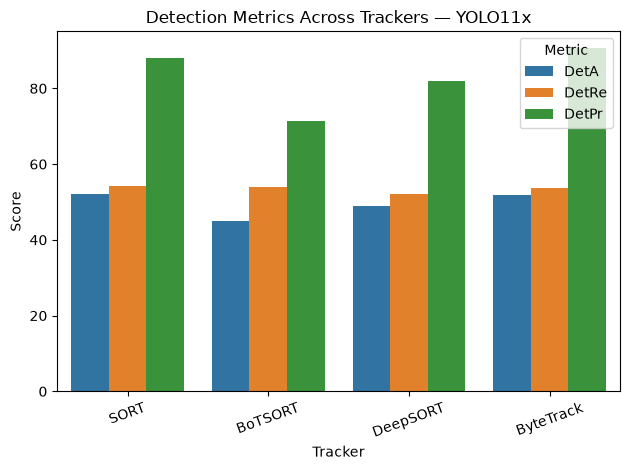

In [36]:
yolo11x_df = df[df["Detector"] == "YOLO11x"]

metric_cols = ["DetA", "DetRe", "DetPr"]

plot_df = yolo11x_df.melt(
    id_vars="Tracker",
    value_vars=metric_cols,
    var_name="Metric",
    value_name="Value"
)
print(plot_df)

sns.barplot(
    data=plot_df,
    x="Tracker",
    y="Value",
    hue="Metric"
)

plt.title("Detection Metrics Across Trackers — YOLO11x")
plt.xlabel("Tracker")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### YOLO version × model size

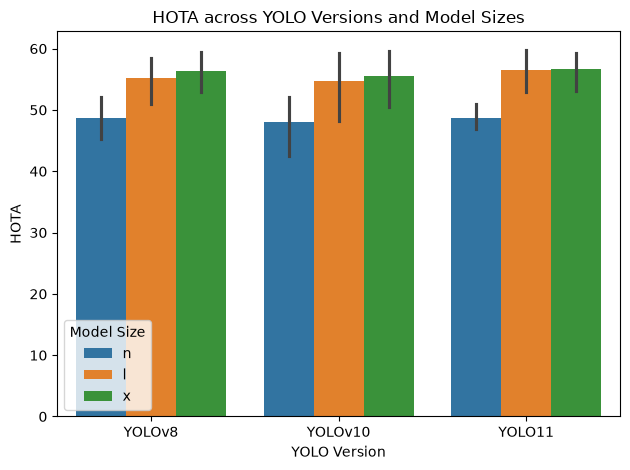

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

plot_df = (
    df.assign(
        version=df["Detector"].str.extract(r"(YOLO(?:v)?\d+)"),
        size=df["Detector"].str.extract(r"([nslmx])$")
    )
)

sns.barplot(
    data=plot_df,
    x="version",
    y="HOTA",
    hue="size"
)

plt.title("HOTA across YOLO Versions and Model Sizes")
plt.xlabel("YOLO Version")
plt.ylabel("HOTA")
plt.legend(title="Model Size")
plt.tight_layout()
plt.show()

#### Detected detections vs ground-truth detections

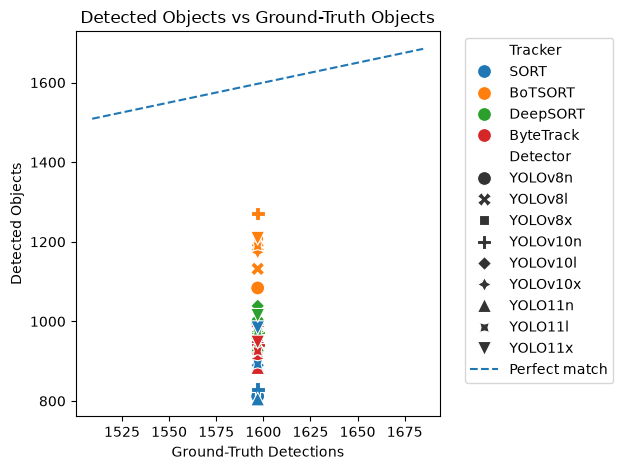

In [44]:
sns.scatterplot(
    data=df,
    x="GT_Det",
    y="Det",
    hue="Tracker",
    style="Detector",
    s=100
)

# Perfect detection line
lims = plt.xlim()
plt.plot(lims, lims, "--", label="Perfect match")

plt.title("Detected Objects vs Ground-Truth Objects")
plt.xlabel("Ground-Truth Detections")
plt.ylabel("Detected Objects")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()